# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [34]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'claym2'   # <-- set this
# d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
d = np.genfromtxt('../../labs/07/data/claym2.csv', delimiter=',', names=True)

t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

254 epochs over 968 days; median quoted error 0.039 mag; rms of the light curve 0.243 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


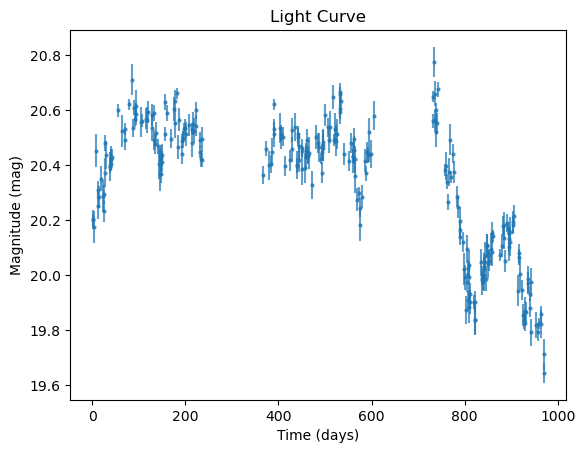

In [13]:
plt.errorbar(t, y, yerr=e, fmt='.', markersize=4, alpha=0.7)

plt.xlabel('Time (days)')
plt.ylabel('Magnitude (mag)')
plt.title('Light Curve')
plt.show()

Highest peak period: 484.04 days
Peak power: 0.3592
False-alarm probability: 2.5639e-22


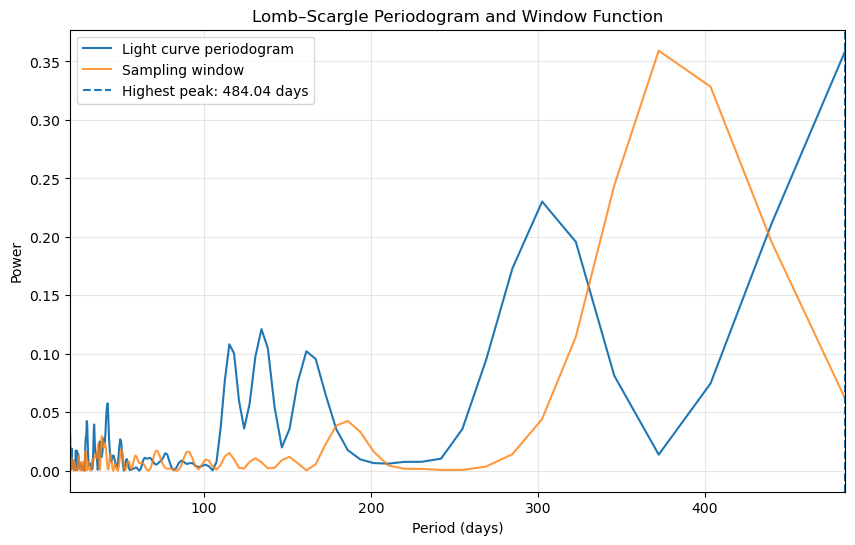

In [14]:
# Frequency range
fmin = 2 / T       # Corresponds to a period of T/2
fmax = 1 / 20      # Corresponds to a period of 20 days

# Frequency spacing: no coarser than 1/(5T)
df = 1 / (5 * T)
frequency = np.arange(fmin, fmax + df, df)

# Lomb-Scargle periodogram using the measurement errors
ls = LombScargle(t, y, dy=e)
power = ls.power(frequency)

# Convert frequency to period
period = 1 / frequency

# Find the strongest peak
best_index = np.argmax(power)
best_period = period[best_index]
best_power = power[best_index]

# Calculate false-alarm probability
fap = ls.false_alarm_probability(
    best_power,
    minimum_frequency=fmin,
    maximum_frequency=fmax
)

print(f"Highest peak period: {best_period:.2f} days")
print(f"Peak power: {best_power:.4f}")
print(f"False-alarm probability: {fap:.6g}")

# Calculate the sampling window function
window_ls = LombScargle(
    t,
    np.ones_like(y),
    fit_mean=False,
    center_data=False
)

window_power = window_ls.power(frequency)

# Scale the window to the same maximum as the periodogram
window_power = window_power * (power.max() / window_power.max())

# Plot both
plt.figure(figsize=(10, 6))

plt.plot(period, power, label='Light curve periodogram')
plt.plot(period, window_power, label='Sampling window', alpha=0.8)

plt.axvline(best_period, linestyle='--',
            label=f'Highest peak: {best_period:.2f} days')

plt.xlabel('Period (days)')
plt.ylabel('Power')
plt.title('Lomb–Scargle Periodogram and Window Function')
plt.xlim(20, T / 2)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**ANSWER (a few sentences):**

Lomb-Scargle peaks at around 484.04 days, with a power of 0.3592. There are several other smaller peaks around 0-200 days which could be caused by sampling patterns. They are incredibly faint in power as well. Searching beyond T/2 could be tricky as longer periods do not have enough time to cycle in teh observation, making them hard to distinguish. Astropy calculates the false-alarm probability using a noise model that does not account for the correlated DRW variability we expect to see in a quasar, making a super tiny value alone not enough to prove periodicity. The false-alarm probabiltiy assumes the probability of getting a peak at least as strong without a periodic signal. 

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ 0.5633 (+0.4474 / −0.2519) mag, $\tau = $ 718 (+1597 / −506.9) d, $T/\tau = $ 1.348; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 315.3691; 30 of 48  DWR held-out points are inside the 68% band.


DRW maximum-likelihood results
mu = 20.2751 mag
sigma = 0.2819 mag
tau = 172.46 days
T/tau = 5.613
Maximum ln L = 315.3691

Check all starting values:
Start sigma=0.1, tau=50: ln L=315.3691, success=True
Start sigma=0.3, tau=300: ln L=315.3691, success=True
Start sigma=0.5, tau=1500: ln L=315.3691, success=True
Start sigma=1.0, tau=3500: ln L=315.3691, success=True


You must install the tqdm library to use progress indicators with emcee



Posterior medians and 68% intervals
mu = 20.2 (+0.3678 / -0.5163) mag
sigma = 0.5633 (+0.4474 / -0.2519) mag
tau = 718 (+1597 / -506.9) days
T/tau = 1.348 (+3.239 / -0.9301) 

Estimated integrated autocorrelation times: [38.81074811 38.12507208 37.5579177 ]
Chain length / largest autocorrelation time: 64.41514585092763


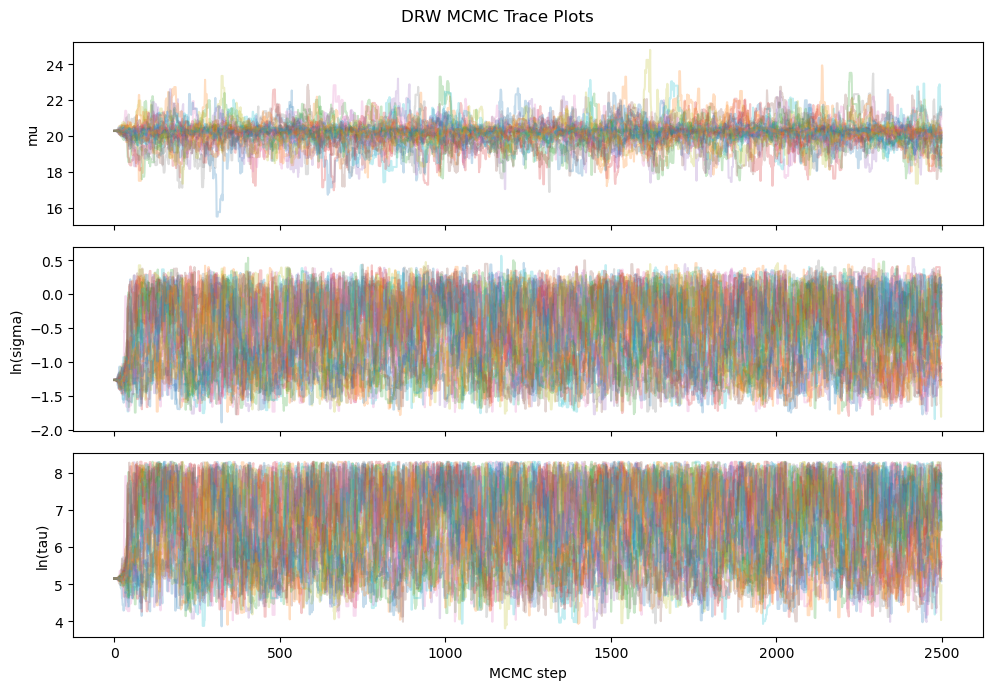


Kernel comparison
DRW maximum ln L = 315.3691
SE maximum ln L = 268.1360
Delta ln L (DRW - SE) = 47.2331
Higher-likelihood kernel: drw


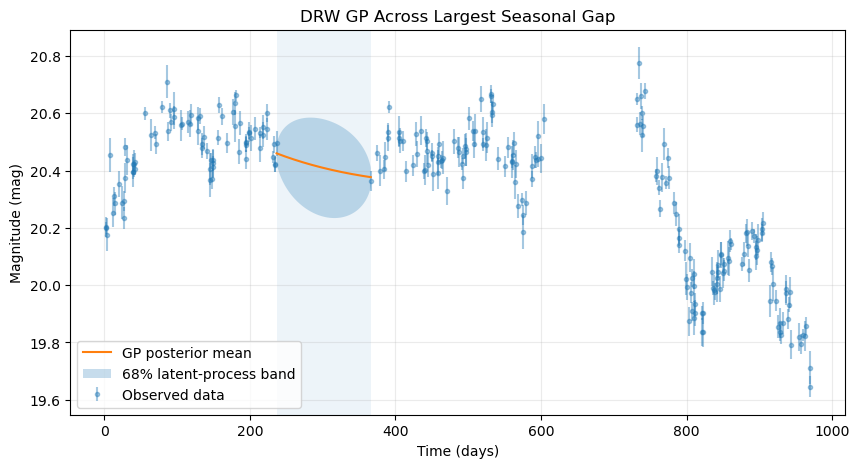

Largest gap: 129.5 days
The plotted band is for the latent light curve, not new noisy measurements.

Holdout block start times: [np.float64(57.0), np.float64(434.0), np.float64(567.0), np.float64(798.0)]
Held-out points: 48

DRW holdout results
Inside predictive 68% band: 30 / 48
Fraction inside: 0.625
R² against training mean: 0.802

SE holdout results
Inside predictive 68% band: 28 / 48
Fraction inside: 0.583
R² against training mean: 0.451


In [27]:

# PART 2: Gaussian Process Analysis
# Requires t, y, e, T from the original data-loading cell.

import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve

# --------------------------------------------------
# 1. Likelihood, prior, and posterior
# --------------------------------------------------

dt = np.abs(t[:, None] - t[None, :])
N = len(y)


def log_likelihood(theta, kernel="drw", t_data=t, y_data=y, e_data=e):
    mu, ln_sigma, ln_tau = theta
    sigma, tau = np.exp(ln_sigma), np.exp(ln_tau)

    dt_local = np.abs(t_data[:, None] - t_data[None, :])

    if kernel == "drw":
        K_local = sigma**2 * np.exp(-dt_local / tau)
    elif kernel == "se":
        K_local = sigma**2 * np.exp(-0.5 * (dt_local / tau)**2)
    else:
        raise ValueError("kernel must be 'drw' or 'se'")

    C_local = K_local + np.diag(e_data**2)

    try:
        factor, lower = cho_factor(C_local, lower=True)
        residual = y_data - mu
        solved = cho_solve((factor, lower), residual)
        logdet = 2 * np.log(np.diag(factor)).sum()

        return -0.5 * (
            residual @ solved + logdet
            + len(y_data) * np.log(2 * np.pi)
        )
    except np.linalg.LinAlgError:
        return -np.inf


def log_prior(theta):
    _, ln_sigma, ln_tau = theta

    if (np.log(0.01) < ln_sigma < np.log(3.0)
            and np.log(10) < ln_tau < np.log(4000)):
        return 0.0

    return -np.inf


def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)


# --------------------------------------------------
# 2. Maximum-likelihood fits from multiple starts
# --------------------------------------------------

def fit_model(kernel="drw", t_data=t, y_data=y, e_data=e):
    # Define these locally so a previous variable cannot overwrite them.
    bounds_local = [
        (y_data.min() - 2, y_data.max() + 2),
        (np.log(0.01), np.log(3.0)),
        (np.log(10), np.log(4000))
    ]

    starts_local = [
        [np.median(y_data), np.log(s), np.log(tau)]
        for s, tau in [
            (0.1, 50), (0.3, 300),
            (0.5, 1500), (1.0, 3500)
        ]
    ]

    results = []
    for start in starts_local:
        result = minimize(
            lambda p: -log_likelihood(
                p, kernel, t_data, y_data, e_data
            ),
            start,
            method="L-BFGS-B",
            bounds=bounds_local
        )
        if result.success and np.isfinite(result.fun):
            results.append(result)

    if not results:
        raise RuntimeError(f"All {kernel} optimizer starts failed.")

    return min(results, key=lambda result: result.fun)


drw_fit = fit_model("drw")
se_fit = fit_model("se")

mu_hat, ln_sigma_hat, ln_tau_hat = drw_fit.x
sigma_hat, tau_hat = np.exp(ln_sigma_hat), np.exp(ln_tau_hat)

print("DRW maximum-likelihood results")
print(f"mu = {mu_hat:.4f} mag")
print(f"sigma = {sigma_hat:.4f} mag")
print(f"tau = {tau_hat:.2f} days")
print(f"T/tau = {T/tau_hat:.3f}")
print(f"Maximum ln L = {-drw_fit.fun:.4f}")

print("\nCheck all starting values:")
for s, tau_start in [(0.1, 50), (0.3, 300),
                     (0.5, 1500), (1.0, 3500)]:
    start = [np.median(y), np.log(s), np.log(tau_start)]
    result = minimize(
        lambda p: -log_likelihood(p, "drw"),
        start, method="L-BFGS-B",
        bounds=[
            (y.min()-2, y.max()+2),
            (np.log(0.01), np.log(3.0)),
            (np.log(10), np.log(4000))
        ]
    )
    print(f"Start sigma={s}, tau={tau_start}: "
          f"ln L={-result.fun:.4f}, success={result.success}")


# --------------------------------------------------
# 3. MCMC uncertainty estimates for the DRW
# --------------------------------------------------

ndim, nwalkers = 3, 32
rng = np.random.default_rng(42)

initial = drw_fit.x + 1e-3 * rng.normal(size=(nwalkers, ndim))

# Keep starting walkers inside the prior bounds.
initial[:, 1] = np.clip(
    initial[:, 1], np.log(0.01001), np.log(2.999)
)
initial[:, 2] = np.clip(
    initial[:, 2], np.log(10.01), np.log(3999)
)

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
sampler.run_mcmc(initial, 2500, progress=True)

samples = sampler.get_chain(discard=800, flat=True)
mu_samples = samples[:, 0]
sigma_samples = np.exp(samples[:, 1])
tau_samples = np.exp(samples[:, 2])

def report_interval(name, values, unit=""):
    q16, q50, q84 = np.percentile(values, [16, 50, 84])
    print(f"{name} = {q50:.4g} (+{q84-q50:.4g} / "
          f"-{q50-q16:.4g}) {unit}")
    return q16, q50, q84

print("\nPosterior medians and 68% intervals")
report_interval("mu", mu_samples, "mag")
report_interval("sigma", sigma_samples, "mag")
tau_low, tau_med, tau_high = report_interval(
    "tau", tau_samples, "days"
)
report_interval("T/tau", T / tau_samples)

try:
    autocorr = sampler.get_autocorr_time(tol=0)
    print("\nEstimated integrated autocorrelation times:", autocorr)
    print("Chain length / largest autocorrelation time:",
          sampler.iteration / np.max(autocorr))
except Exception as exc:
    print("\nAutocorrelation-time check failed:", exc)

# Trace plots for checking mixing and convergence.
chain = sampler.get_chain()
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for j, label in enumerate(["mu", "ln(sigma)", "ln(tau)"]):
    axes[j].plot(chain[:, :, j], alpha=0.25)
    axes[j].set_ylabel(label)

axes[-1].set_xlabel("MCMC step")
fig.suptitle("DRW MCMC Trace Plots")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Compare the DRW and squared-exponential kernels
# --------------------------------------------------

lnL_drw = -drw_fit.fun
lnL_se = -se_fit.fun
delta_lnL = lnL_drw - lnL_se

print("\nKernel comparison")
print(f"DRW maximum ln L = {lnL_drw:.4f}")
print(f"SE maximum ln L = {lnL_se:.4f}")
print(f"Delta ln L (DRW - SE) = {delta_lnL:.4f}")

best_kernel = "drw" if delta_lnL >= 0 else "se"
best_fit = drw_fit if best_kernel == "drw" else se_fit
print("Higher-likelihood kernel:", best_kernel)


# --------------------------------------------------
# 5. GP prediction function
# --------------------------------------------------

def gp_predict(theta, t_train, y_train, e_train, t_pred,
               kernel="drw", include_noise=False, e_pred=None):
    mu, ln_sigma, ln_tau = theta
    sigma, tau = np.exp(ln_sigma), np.exp(ln_tau)

    d_train = np.abs(t_train[:, None] - t_train[None, :])
    d_cross = np.abs(t_pred[:, None] - t_train[None, :])
    d_pred = np.abs(t_pred[:, None] - t_pred[None, :])

    if kernel == "drw":
        K_train = sigma**2 * np.exp(-d_train / tau)
        K_cross = sigma**2 * np.exp(-d_cross / tau)
        K_pred = sigma**2 * np.exp(-d_pred / tau)
    else:
        K_train = sigma**2 * np.exp(-0.5 * (d_train/tau)**2)
        K_cross = sigma**2 * np.exp(-0.5 * (d_cross/tau)**2)
        K_pred = sigma**2 * np.exp(-0.5 * (d_pred/tau)**2)

    C_train = K_train + np.diag(e_train**2)
    factor = cho_factor(C_train, lower=True)

    residual = y_train - mu
    alpha = cho_solve(factor, residual)
    mean = mu + K_cross @ alpha

    v = cho_solve(factor, K_cross.T)
    variance = np.maximum(
        np.diag(K_pred - K_cross @ v), 0
    )

    if include_noise:
        if e_pred is None:
            raise ValueError("e_pred is required for measurement noise.")
        variance += e_pred**2

    std = np.sqrt(variance)
    return mean, mean - std, mean + std


# Plot the prediction across the largest seasonal gap.
sorted_t = np.sort(t)
gaps = np.diff(sorted_t)
gap_index = np.argmax(gaps)
gap_start, gap_end = sorted_t[gap_index:gap_index+2]

t_grid = np.linspace(gap_start, gap_end, 300)
pred_mean, pred_low, pred_high = gp_predict(
    best_fit.x, t, y, e, t_grid, kernel=best_kernel
)

plt.figure(figsize=(10, 5))
plt.errorbar(t, y, yerr=e, fmt=".", alpha=0.4,
             label="Observed data")
plt.plot(t_grid, pred_mean, label="GP posterior mean")
plt.fill_between(t_grid, pred_low, pred_high, alpha=0.25,
                 label="68% latent-process band")
plt.axvspan(gap_start, gap_end, alpha=0.08)
plt.xlabel("Time (days)")
plt.ylabel("Magnitude (mag)")
plt.title(f"{best_kernel.upper()} GP Across Largest Seasonal Gap")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Largest gap: {gap_end-gap_start:.1f} days")
print("The plotted band is for the latent light curve, not new noisy measurements.")


# --------------------------------------------------
# 6. Four held-out 30-day blocks
# --------------------------------------------------

# Observing seasons are separated by gaps greater than 60 days.
order = np.argsort(t)
sorted_t = t[order]
season_breaks = np.where(np.diff(sorted_t) > 60)[0] + 1
seasons = np.split(sorted_t, season_breaks)

candidates = []
for season in seasons:
    if len(season) < 2 or season[-1] - season[0] < 30:
        continue

    for start in np.arange(
        np.ceil(season[0]), np.floor(season[-1] - 30) + 1, 1
    ):
        mask = (t >= start) & (t < start + 30)
        if mask.any():
            candidates.append((start, mask))

if len(candidates) < 4:
    raise RuntimeError("Not enough candidate 30-day blocks.")

rng = np.random.default_rng(42)
selected = None

for _ in range(50000):
    choices = rng.choice(len(candidates), size=4, replace=False)
    blocks = sorted([candidates[i] for i in choices],
                    key=lambda item: item[0])

    # At least 60 days between the end of one block and start of next.
    if all(blocks[i+1][0] >= blocks[i][0] + 90
           for i in range(3)):
        selected = blocks
        break

if selected is None:
    raise RuntimeError(
        "Could not find four valid separated blocks; inspect the seasons."
    )

holdout = np.zeros(len(t), dtype=bool)
for start, mask in selected:
    holdout |= mask

t_train, y_train, e_train = t[~holdout], y[~holdout], e[~holdout]
t_test, y_test, e_test = t[holdout], y[holdout], e[holdout]

print("\nHoldout block start times:",
      [round(start, 1) for start, _ in selected])
print("Held-out points:", len(y_test))


def evaluate_holdout(kernel):
    fit = fit_model(kernel, t_train, y_train, e_train)

    mean, low, high = gp_predict(
        fit.x, t_train, y_train, e_train, t_test,
        kernel=kernel, include_noise=True, e_pred=e_test
    )

    inside = (y_test >= low) & (y_test <= high)
    coverage = inside.mean()

    # R² uses the training mean as the baseline.
    ss_res = np.sum((y_test - mean)**2)
    ss_tot = np.sum((y_test - np.mean(y_train))**2)
    r2 = 1 - ss_res / ss_tot

    print(f"\n{kernel.upper()} holdout results")
    print(f"Inside predictive 68% band: {inside.sum()} / {len(y_test)}")
    print(f"Fraction inside: {coverage:.3f}")
    print(f"R² against training mean: {r2:.3f}")

    return fit, mean, low, high, coverage, r2


drw_test = evaluate_holdout("drw")
se_test = evaluate_holdout("se")


**FINAL ANSWER:** 

I decided to report the MCMC posterior DRW method, though the results are not perfect. The amplitude is sigma = 0.5633^{+0.4474-0.2519} mag, and the median damping time is tau = 718^{+1597-506.9} days. The corresponding baseline ratio is T/\tau = 1.348^{+3.239-0.9301}. The maximum-likelihood fit gives ln L=315.3691 for the DRW kernel and ln L=268.1360 for the squared-exponential kernel, so the DRW kernel is favored by Delta\ln L=47.2331. For the DRW holdout test, 30 of 48 held-out observations (62.5%) fell inside the 68% predictive band, with (R^2=0.802). For the squared-exponential kernel, 28 of 48 (58.3%) fell inside the band, with (R^2=0.451).

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


Simulations: 1000
Observed maximum power: 0.35918592436003344
Simulated maxima at least as high: 468
Empirical p-value: 0.46853146853146854


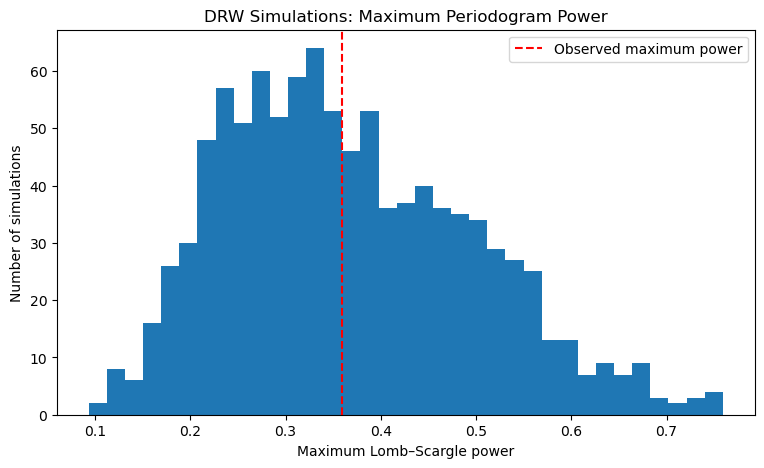

In [28]:
# Part 3: DRW simulations
rng = np.random.default_rng(42)
nsim = 1000

# DRW covariance at the actual observation times
dt = np.abs(t[:, None] - t[None, :])
K = sigma_hat**2 * np.exp(-dt / tau_hat)

# Cholesky factor of the intrinsic DRW covariance
L = np.linalg.cholesky(K + 1e-10 * np.eye(len(t)))

simulated_max_power = np.zeros(nsim)

for i in range(nsim):

    # Draw correlated DRW variability
    z = rng.normal(size=len(t))
    drw = L @ z

    # Add independent measurement noise
    noise = rng.normal(0, e, size=len(t))
    y_sim = mu_hat + drw + noise

    # Search the same period range
    ls_sim = LombScargle(t, y_sim, dy=e)
    power_sim = ls_sim.power(frequency)

    # Record the maximum power, not the power at one fixed period
    simulated_max_power[i] = np.max(power_sim)

# Empirical p-value, with a small-sample correction
n_exceed = np.sum(simulated_max_power >= best_power)
p_empirical = (n_exceed + 1) / (nsim + 1)

print("Simulations:", nsim)
print("Observed maximum power:", best_power)
print("Simulated maxima at least as high:", n_exceed)
print("Empirical p-value:", p_empirical)

plt.figure(figsize=(9, 5))
plt.hist(simulated_max_power, bins=35)
plt.axvline(best_power, linestyle='--',
            label='Observed maximum power', color="red")
plt.xlabel('Maximum Lomb–Scargle power')
plt.ylabel('Number of simulations')
plt.title('DRW Simulations: Maximum Periodogram Power')
plt.legend()
plt.show()

In [20]:
print("Astropy false-alarm probability:", fap)
print("Empirical DRW p-value:", p_empirical)

Astropy false-alarm probability: 2.5638993429977844e-22
Empirical DRW p-value: 0.46853146853146854


In [21]:
# Build the DRW covariance including measurement errors
C = K + np.diag(e**2)
C_factor = cho_factor(C, lower=True)
Cinv = cho_solve(C_factor, np.eye(len(t)))

# Constant-mean model
one = np.ones(len(t))
Cinv_one = Cinv @ one
denom_mu = one @ Cinv_one

def delta_chi2_for_data(y_values):
    """
    Return the maximum improvement over a constant mean,
    scanning every frequency in the existing grid.
    """
    residual = y_values - one * (
        (one @ Cinv @ y_values) / denom_mu
    )
    chi2_const = residual @ Cinv @ residual

    best_delta = -np.inf
    best_result = None

    for f in frequency:
        phase = 2 * np.pi * f * t
        X = np.column_stack([
            one, np.cos(phase), np.sin(phase)
        ])

        beta = np.linalg.solve(
            X.T @ Cinv @ X,
            X.T @ Cinv @ y_values
        )

        residual_full = y_values - X @ beta
        chi2_full = residual_full @ Cinv @ residual_full
        delta = chi2_const - chi2_full

        if delta > best_delta:
            best_delta = delta
            best_result = (1 / f, beta, chi2_const, chi2_full)

    return best_delta, best_result


observed_delta, best_sinusoid = delta_chi2_for_data(y)
best_sinusoid_period, best_beta, chi2_const, chi2_sinusoid = best_sinusoid

best_amplitude = np.sqrt(best_beta[1]**2 + best_beta[2]**2)

print("Best sinusoidal period:", best_sinusoid_period, "days")
print("Best sinusoidal amplitude:", best_amplitude, "mag")
print("Maximum delta chi-square:", observed_delta)

Best sinusoidal period: 23.72737745098038 days
Best sinusoidal amplitude: 0.02502812949882178 mag
Maximum delta chi-square: 9.86921050214329


Observed maximum delta chi-square: 9.86921050214329
Simulated maxima at least as high: 529
Empirical sinusoidal-test p-value: 0.5294705294705294


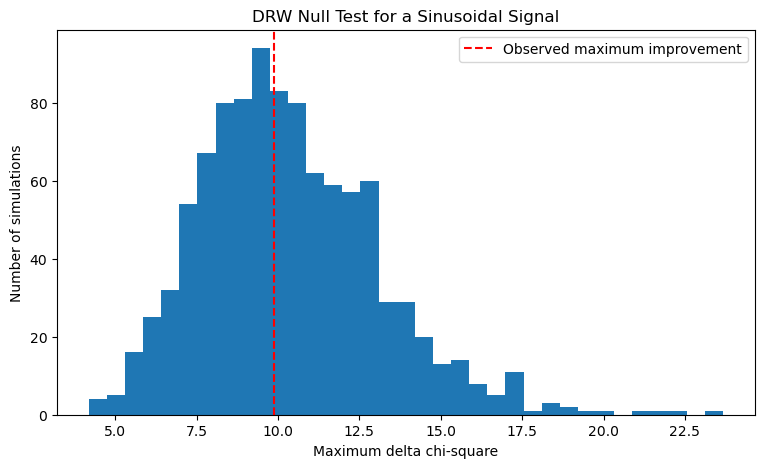

In [26]:
# Reuse the same fitted DRW null model and sampling
rng = np.random.default_rng(123)
simulated_delta = np.zeros(nsim)

for i in range(nsim):
    drw = L @ rng.normal(size=len(t))
    noise = rng.normal(0, e, size=len(t))
    y_sim = mu_hat + drw + noise

    simulated_delta[i], _ = delta_chi2_for_data(y_sim)

n_exceed_delta = np.sum(simulated_delta >= observed_delta)
p_delta = (n_exceed_delta + 1) / (nsim + 1)

print("Observed maximum delta chi-square:", observed_delta)
print("Simulated maxima at least as high:", n_exceed_delta)
print("Empirical sinusoidal-test p-value:", p_delta)

plt.figure(figsize=(9, 5))
plt.hist(simulated_delta, bins=35)
plt.axvline(observed_delta, linestyle='--',
            label='Observed maximum improvement', color="red")
plt.xlabel('Maximum delta chi-square')
plt.ylabel('Number of simulations')
plt.title('DRW Null Test for a Sinusoidal Signal')
plt.legend()
plt.show()

In [23]:
tau_low, tau_med, tau_high = np.percentile(
    tau_samples, [16, 50, 84]
)

def periodogram_p_for_tau(tau_value, nsim=1000, seed=42):
    rng = np.random.default_rng(seed)

    K_tau = sigma_hat**2 * np.exp(-dt / tau_value)
    L_tau = np.linalg.cholesky(
        K_tau + 1e-10 * np.eye(len(t))
    )

    maxima = np.zeros(nsim)

    for i in range(nsim):
        y_sim = (
            mu_hat
            + L_tau @ rng.normal(size=len(t))
            + rng.normal(0, e, size=len(t))
        )

        maxima[i] = np.max(
            LombScargle(t, y_sim, dy=e).power(frequency)
        )

    count = np.sum(maxima >= best_power)
    return (count + 1) / (nsim + 1)

p_low_tau = periodogram_p_for_tau(tau_low)
p_high_tau = periodogram_p_for_tau(tau_high)

print("Tau 16th percentile:", tau_low)
print("Empirical p-value at lower tau:", p_low_tau)
print("Tau 84th percentile:", tau_high)
print("Empirical p-value at upper tau:", p_high_tau)

Tau 16th percentile: 207.39110289851936
Empirical p-value at lower tau: 0.4695304695304695
Tau 84th percentile: 2302.313003236457
Empirical p-value at upper tau: 0.36663336663336665


**ANSWER (the decision rule first, then the verdict):**

Initial markdown for p: I would accept that the p-value would need to be below 0.01 or so. We want to limit the probability to around 1% of falsely showing a periodic signal. 

While running the Lomb-Scargle, the power excedded by 468 of the 1000 simulations, giving a p-value of 0.468. This is drastically different from the white-noise of 2.56E-22 because this model works with the correlated variability to correctly predict the peaks. Based on my initial conclusion, I would not claim that there is a period within the range specified. The DRW found a "best period" around 23.7 days with an amplitude of 0.025 mag, however 529 of the 1000 simulations produced something equal or larger power, p=0.529. The upper and lower empirical p-values od 0.46 and 0.36 respectively did not approach the 0.01 threshold I placed. Based on all of this, it is not in the group's best interest to state that there is a binary candidate.

In [39]:

# Save results from Parts 1–3 before Part 5 can overwrite variables.

# Part 1: Lomb–Scargle periodogram
part3_fap = fap
part3_period = best_period
part3_power = best_power

# Part 2: GP kernel comparison
part2_drw_loglike = -drw_fit.fun
part2_se_loglike = -se_fit.fun
part2_delta_loglike = part2_drw_loglike - part2_se_loglike

# Part 3: DRW simulation test
part3_p_empirical = p_empirical

# Part 3: DRW-aware sinusoidal test
part3_best_sinusoid_period = best_sinusoid_period
part3_best_amplitude = best_amplitude
part3_observed_delta = observed_delta
part3_p_delta = p_delta

# Save the original simulated-light-curve sample size.
part3_n_observations = len(y)

print("Part 1–3 results saved.")


Part 1–3 results saved.


## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


Issue 1: Initially, I am very confused about their 0.923 R-squared while returning a 56% converage. Even though the corss-validation returned 0.923, the AI report said that 56% of the held observations fall inside the 68% prediction range. The lower than expected number could suggest that uncertainties are too narrow, meaning they should be expanded a little. To fix this, we want to hold non-overlapping day blocks, fitting the model to the remaining observations. Just a high R-squared alone does not demonstrate that the uncertanties are valid for this model. 

Issue 2: They reported some period uncertainty of about 11 days around 484, but we know that the curve contains correlated variability and the calculation used to get that range does not account for that, nor does it show whether the signal is actaully periodic or not. The DRW test above provides more evidence and they end up getting a chi-squared of 9.87, yet still a p-value of 0.529. The correct thing to do is estimate the period and amplitude with a model that accounts for the correlated noise that we know exists and re-test. 

Issue 3: Lastly, the errors on the period seems weird. They seem to state that because the false alarm probability is low, that means there must be a peak there. However, the probability is calcualted using noise that does not account for correlation that can be observed through other means in the DRW. To test this, we simulated 1000 DRW light curves, recording the maximum power across the same range. I ended up getting hundreds that produced a peak at least as high as the actual observed one, giving a p-value of about 0.46, drastically differing from the 10^-22 number. 

In [40]:

print("1. Part 1: Periodogram")
print(f"White-noise FAP: {part3_fap:.3e}")
print(f"Highest-peak period: {part3_period:.2f} days")
print(f"Maximum Lomb–Scargle power: {part3_power:.4f}")

print("\n2. Part 2: Kernel comparison")
print(f"DRW maximum ln L: {part2_drw_loglike:.3f}")
print(f"SE maximum ln L: {part2_se_loglike:.3f}")
print(f"Delta ln L (DRW - SE): {part2_delta_loglike:.3f}")

print("\n3. Part 3: DRW periodicity test")
print(f"Empirical DRW p-value: {part3_p_empirical:.3f}")

print("\n4. Part 3: DRW-aware sinusoidal test")
print(f"Best sinusoidal period: {part3_best_sinusoid_period:.2f} days")
print(f"Sinusoidal amplitude: {part3_best_amplitude:.4f} mag")
print(f"Maximum delta chi-square: {part3_observed_delta:.3f}")
print(f"Empirical p-value: {part3_p_delta:.3f}")

print("\n5. Part 4: AI cross-validation results")

# These values are from the separate ai_solution notebook.
r2_ai = 0.923
cover_ai = 0.56

print(f"AI R-squared: {r2_ai:.3f}")
print(f"AI 68% prediction-band coverage: {100 * cover_ai:.1f}%")
print(
    f"Expected count at 68% coverage: "
    f"{0.68 * part3_n_observations:.1f}"
)
print(
    f"Approximate count at 56% coverage: "
    f"{cover_ai * part3_n_observations:.1f}"
)


1. Part 1: Periodogram
White-noise FAP: 2.564e-22
Highest-peak period: 484.04 days
Maximum Lomb–Scargle power: 0.3592

2. Part 2: Kernel comparison
DRW maximum ln L: 315.369
SE maximum ln L: 268.136
Delta ln L (DRW - SE): 47.233

3. Part 3: DRW periodicity test
Empirical DRW p-value: 0.993

4. Part 3: DRW-aware sinusoidal test
Best sinusoidal period: 23.73 days
Sinusoidal amplitude: 0.0250 mag
Maximum delta chi-square: 9.869
Empirical p-value: 0.529

5. Part 4: AI cross-validation results
AI R-squared: 0.923
AI 68% prediction-band coverage: 56.0%
Expected count at 68% coverage: 382.2
Approximate count at 56% coverage: 314.7


## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [35]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('../../labs/07/data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18abaljsv: 782 g-band detections from the live API
ZTF18abaljsv: MJD 58304.2 to 61076.2 (7.6 yr); the last detection is MJD 61076.2; today is MJD 61341


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


We will say that evidence for periodicity exists if the empirical p-vlaue from the 1000 silumated DRW light curves is below 0.01. For each simulation, the max power over the period range will be recorded and I will calculate the fraction of simulated maxima that is at least as large as the observed maxima.

Nightly means: 562 observations over 7.6 years
Observed maximum power: 0.1239
Period at maximum power: 322.32 days
DRW mu: 17.1335
DRW sigma: 0.2190
DRW tau: 529.1 days
Simulations at least as extreme: 993/1000
Empirical p-value: 0.9930
Periodic by predeclared criterion: False


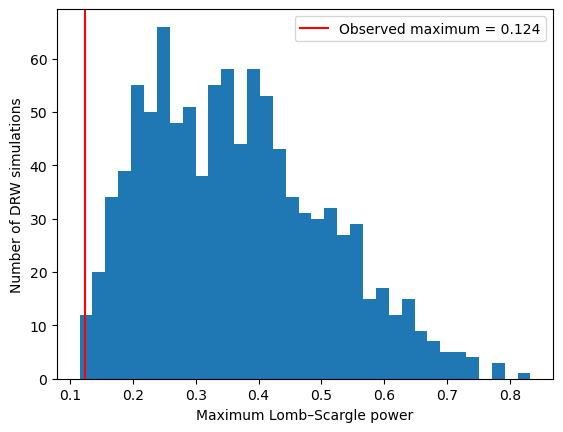

In [37]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from astropy.timeseries import LombScargle

# 1. Combine observations from the same night using weighted means
night = np.floor(mjd)
t, y, e = [], [], []

for n in np.unique(night):
    mask = night == n
    weights = 1 / merr[mask]**2
    t.append(np.average(mjd[mask], weights=weights))
    y.append(np.average(mag[mask], weights=weights))
    e.append(np.sqrt(1 / weights.sum()))

t = np.array(t)
y = np.array(y)
e = np.array(e)

# Sort observations by time
order = np.argsort(t)
t, y, e = t[order], y[order], e[order]

T = t.max() - t.min()
print(f"Nightly means: {len(t)} observations over {T / 365.25:.1f} years")

# 2. Define the Lomb–Scargle frequency grid
# Period range: 20 days to T/2
freq = np.arange(2 / T, 1 / 20, 1 / (5 * T))
ls = LombScargle(t, y, e, fit_mean=True, center_data=True)
power = ls.power(freq)
observed_max = power.max()
observed_period = 1 / freq[np.argmax(power)]

print(f"Observed maximum power: {observed_max:.4f}")
print(f"Period at maximum power: {observed_period:.2f} days")

# 3. Fit a DRW model using the measurement errors
def drw_loglike(params):
    mu, log_sigma, log_tau = params
    sigma = np.exp(log_sigma)
    tau = np.exp(log_tau)

    dt = np.abs(t[:, None] - t[None, :])
    C = sigma**2 * np.exp(-dt / tau)
    C[np.diag_indices_from(C)] += e**2

    try:
        L = np.linalg.cholesky(C)
        residual = y - mu
        z = np.linalg.solve(L, residual)
        return -0.5 * (
            z @ z
            + 2 * np.log(np.diag(L)).sum()
            + len(y) * np.log(2 * np.pi)
        )
    except np.linalg.LinAlgError:
        return -np.inf

bounds = [
    (y.min() - 2, y.max() + 2),
    (np.log(0.01), np.log(3.0)),
    (np.log(10), np.log(4000))
]

starts = [
    [np.median(y), np.log(0.3), np.log(100)],
    [np.mean(y), np.log(0.5), np.log(500)],
    [np.median(y), np.log(0.2), np.log(1500)]
]

fits = [
    minimize(lambda p: -drw_loglike(p), x0=s, bounds=bounds,
             method="L-BFGS-B")
    for s in starts
]
fit = min(fits, key=lambda result: result.fun)

mu_hat, log_sigma_hat, log_tau_hat = fit.x
sigma_hat = np.exp(log_sigma_hat)
tau_hat = np.exp(log_tau_hat)

print(f"DRW mu: {mu_hat:.4f}")
print(f"DRW sigma: {sigma_hat:.4f}")
print(f"DRW tau: {tau_hat:.1f} days")

# 4. Simulate DRW light curves at the same observation times
# and include the observed measurement errors.
rng = np.random.default_rng(42)
nsim = 1000
simulated_maxima = np.empty(nsim)

dt = np.diff(t)
decay = np.exp(-dt / tau_hat)

for i in range(nsim):
    latent = np.empty(len(t))
    latent[0] = rng.normal(mu_hat, sigma_hat)

    for j in range(1, len(t)):
        latent[j] = (
            mu_hat
            + decay[j - 1] * (latent[j - 1] - mu_hat)
            + sigma_hat * np.sqrt(1 - decay[j - 1]**2)
            * rng.normal()
        )

    y_sim = latent + rng.normal(0, e)

    sim_ls = LombScargle(
        t, y_sim, e, fit_mean=True, center_data=True
    )
    simulated_maxima[i] = sim_ls.power(freq).max()

# 5. Empirical p-value, including the finite-simulation correction
n_exceed = np.sum(simulated_maxima >= observed_max)
p_empirical = (n_exceed + 1) / (nsim + 1)

print(f"Simulations at least as extreme: {n_exceed}/{nsim}")
print(f"Empirical p-value: {p_empirical:.4f}")
print("Periodic by predeclared criterion:", p_empirical < 0.01)

# Plot the observed maximum against the simulated maxima
plt.hist(simulated_maxima, bins=35)
plt.axvline(observed_max, color="red",
            label=f"Observed maximum = {observed_max:.3f}")
plt.xlabel("Maximum Lomb–Scargle power")
plt.ylabel("Number of DRW simulations")
plt.legend()
plt.show()


**ANSWER (the criterion first, then the result):**

The p-value was not close to showing that periodicity exists within the data, coming in at p=0.99. The strongest peak was at 0.124 on the 322nd day. 993 of the 1000 DRW simulations produced a maximum that was equal or higher. For future work, I would inspect the potential sample window and maybe inquire as to if the data was taken during a seasonal off-period. The p-value was terrible and shows that the is not a peak based on my strict choice of p-value above. 

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I used ChatGPT to help interpret the assingment, debut a variety of sections, and understand the DRW and Lomb-Scarble analysis as well as do a comprehensive review of my stats. I personally enjoy using the LLM to suggest me ideas while I verify their validity to fit within the parameters of the assignment. 

**REFLECTION:**

Without checking AI analysis, I would have found that reporting simply the false-alarm probability as what it was and concluding that a peak had existed would have been okay (when it is not). I would have ignored the DRW correlation with variability and learned that R-squared values are not the sole indicator of guaranteed uncertainty. Coverage is also extremely important, as well as p-value calculation ran on thousands of simulated light curves.
**VERIFICATION PLAN:**

I checked whether the maximum-likelihood DRW fit was stable across four starting values; all four returned the same maximum log-likelihood of 315.3691. For periodicity, I simulated 1000 DRW light curves using the same observation times and measurement errors, and compared the maximum periodogram power and the maximum improvement with the  statistics. None of these checks did not show evidence for periodicity.

To verify the uncertainty estimates more thoroughly, I would inspect the MCMC trace plots and test whether posterior summaries are stable across independent chains and longer runs. I would also generate many simulated DRW light curves with known parameters, with and without an injected sinusoid, and run the full fitting and testing pipeline on each. I would assess how often the 68% intervals contain the true parameters and how often the periodicity test detects an injected signal or falsely flags a signal when none was injected. A few hundred or more simulations would be a useful starting point, with the number increased as needed to estimate coverage and false-positive rates precisely. One synthetic light curve alone would not establish that the pipeline is calibrated.